Simple and Multiple Linear Regression: Builiding models,checking assumptions, and evaluating using R^2 and RMSE


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

In [4]:
from google.colab import files
import pandas as pd
uploaded=files.upload()
df=pd.read_csv('housing_clean.csv')
df.head()

Saving housing_clean.csv to housing_clean.csv


,Area,Rooms,Age,Location_Score,Price
0,778,1,6,3,5081030
1,2148,4,27,8,11863210
2,1909,3,3,5,11371453
3,1478,3,16,3,9079771
4,1466,3,14,4,7502204


In [6]:
x_simple = df[['Area']]
y = df['Price']
X_tr, X_te, y_tr, y_te = train_test_split(x_simple, y, test_size=0.2, random_state=42)

model_simple = LinearRegression()
model_simple.fit(X_tr, y_tr)


pred_train = model_simple.predict(X_tr)
pred_test = model_simple.predict(X_te)

print("Simple Regression")
print("R²:", round(r2_score(y_tr, pred_train), 3))
print("RMSE:", round(np.sqrt(mean_squared_error(y_te, pred_test)), 2))

Simple Regression
R²: 0.882
RMSE: 809207.7


In [15]:
X_multi = df[['Area', 'Rooms', 'Age', 'Location_Score']]
X_tr2, X_te2, y_tr2, y_te2 = train_test_split(X_multi, y, test_size=0.2, random_state=42)

model_multi = LinearRegression()
model_multi.fit(X_tr2, y_tr2)
pred_multi = model_multi.predict(X_te2)

print("Multiple Regression")
print("R²:", round(r2_score(y_te2, pred_multi), 3))
print("RMSE:", round(np.sqrt(mean_squared_error(y_te2, pred_multi)), 2))

Multiple Regression
R²: 0.977
RMSE: 495063.19


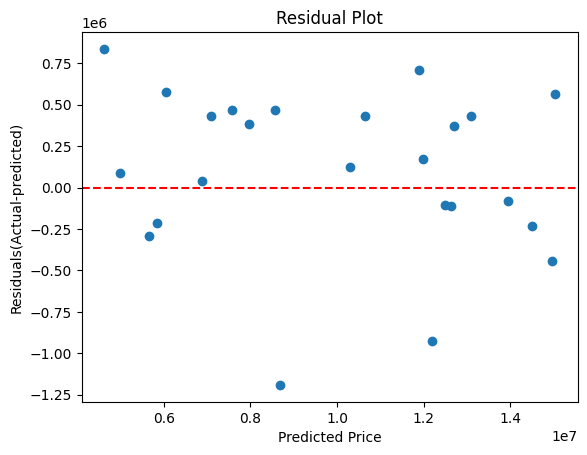

In [16]:
residuals= y_te - pred_multi
plt.scatter(pred_multi, residuals)
plt.axhline(y=0, color='red', linestyle='--')
plt.xlabel('Predicted Price')
plt.ylabel('Residuals(Actual-predicted)')
plt.title('Residual Plot')
plt.show()